In [7]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

current_dir = os.getcwd()
project_root = os.path.dirname(current_dir) if "scripts" in current_dir else current_dir

# 1. Define Paths
city = "pune"
raw_dir = os.path.join(project_root, "data", "raw", city)
processed_dir = os.path.join(project_root, "data", "processed")

# Find the API weather file
weather_files = [f for f in os.listdir(raw_dir) if f.endswith(".csv") and "hourly_rain" in f]
if not weather_files:
    raise FileNotFoundError(f"No hourly weather data found for {city}")

weather_path = os.path.join(raw_dir, weather_files[0])
df = pd.read_csv(weather_path)
df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime').reset_index(drop=True)

print(f"Loaded {len(df)} hours of weather data for {city.upper()}.")

# Clean up any missing data (Linear interpolation)
if df['Precipitation_mm'].isnull().sum() > 0:
    print("Found missing rainfall data. Interpolating...")
    df['Precipitation_mm'] = df['Precipitation_mm'].interpolate(method='linear')
    df = df.fillna(0)

Loaded 43848 hours of weather data for PUNE.


In [8]:
# Load the Ground Truth JSON
json_path = os.path.join(processed_dir, "target_flood_dates.json")
with open(json_path, 'r') as f:
    flood_events = json.load(f)

# Initialize the target column with 0 (No Flood)
df['Flood_Target'] = 0

# If we have flood dates for this city, mark them as 1 (Flood)
if city in flood_events:
    start_date = pd.to_datetime(flood_events[city]['start'])
    end_date = pd.to_datetime(flood_events[city]['end'])
    
    # Create a binary mask where the datetime falls within the flood window
    mask = (df['Datetime'] >= start_date) & (df['Datetime'] <= end_date)
    df.loc[mask, 'Flood_Target'] = 1
    
    print(f"Ground Truth Injected: {df['Flood_Target'].sum()} hours marked as FLOOD EVENTS.")
else:
    print("Warning: No flood dates found for this city. Model cannot train without targets.")

Ground Truth Injected: 289 hours marked as FLOOD EVENTS.


In [9]:
# 1. Scale the Precipitation data
scaler = MinMaxScaler()
df['Precip_Scaled'] = scaler.fit_transform(df[['Precipitation_mm']])

# 2. The Sliding Window Function
def create_sequences(data, targets, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        # The sequence of weather for the last 'window_size' hours
        X.append(data[i:(i + window_size)])
        # The target is whether it flooded exactly AT the end of this window
        y.append(targets[i + window_size])
    return np.array(X), np.array(y)

# We will look at the past 72 hours (3 days) to predict the current hour
WINDOW_SIZE = 72

features = df['Precip_Scaled'].values.reshape(-1, 1)
labels = df['Flood_Target'].values

print("Slicing time-series into 3D tensors... (This takes a few seconds)")
X, y = create_sequences(features, labels, WINDOW_SIZE)

print(f"X Tensor Shape: {X.shape}")
print(f"y Tensor Shape: {y.shape}")

# 3. Dynamic Chronological Split (The Fix for Overfitting)
flood_indices = np.where(y == 1)[0]

if len(flood_indices) > 0:
    # Find the very last hour of the flood
    last_flood_index = flood_indices[-1]
    
    # Make the split 500 hours AFTER the flood ends. 
    split = min(last_flood_index + 500, len(X) - 100) 
else:
    # Fallback if no flood exists
    split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("\n--- NEW DATA SPLIT ---")
print(f"Training set has {y_train.sum()} flood hours.")
print(f"Validation set has {y_test.sum()} flood hours.")

Slicing time-series into 3D tensors... (This takes a few seconds)
X Tensor Shape: (43776, 72, 1)
y Tensor Shape: (43776,)

--- NEW DATA SPLIT ---
Training set has 289 flood hours.
Validation set has 0 flood hours.


Adjusted Class Weights applied: {0: np.float64(0.5038039329244215), 1: 20.0}

Initiating Deep Learning Training...
Epoch 1/30


c:\Users\uberm\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


150/150 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - auc: 0.4742 - loss: 0.3962 - recall: 0.0000e+00 - val_auc: 0.0000e+00 - val_loss: 0.2316 - val_recall: 0.0000e+00
Epoch 2/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc: 0.4761 - loss: 0.3603 - recall: 0.0000e+00 - val_auc: 0.0000e+00 - val_loss: 0.2637 - val_recall: 0.0000e+00
Epoch 3/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - auc: 0.5260 - loss: 0.3549 - recall: 0.0000e+00 - val_auc: 0.0000e+00 - val_loss: 0.2594 - val_recall: 0.0000e+00
Epoch 4/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - auc: 0.5194 - loss: 0.3547 - recall: 0.0000e+00 - val_auc: 0.0000e+00 - val_loss: 0.2665 - val_recall: 0.0000e+00
Epoch 5/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - auc: 0.5675 - loss: 0.3492 - recall: 0.0000e+00 - val_auc: 0.0000e+00 - val_loss: 0.1924 - val_recall: 0.0000e+00
Epoch 6/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - auc: 0.5760 - loss: 0.3473 - recall: 0.0000e+00 - val_auc: 0.0000e+00 - val_loss: 0.2399 - val_recall: 0.0000e+

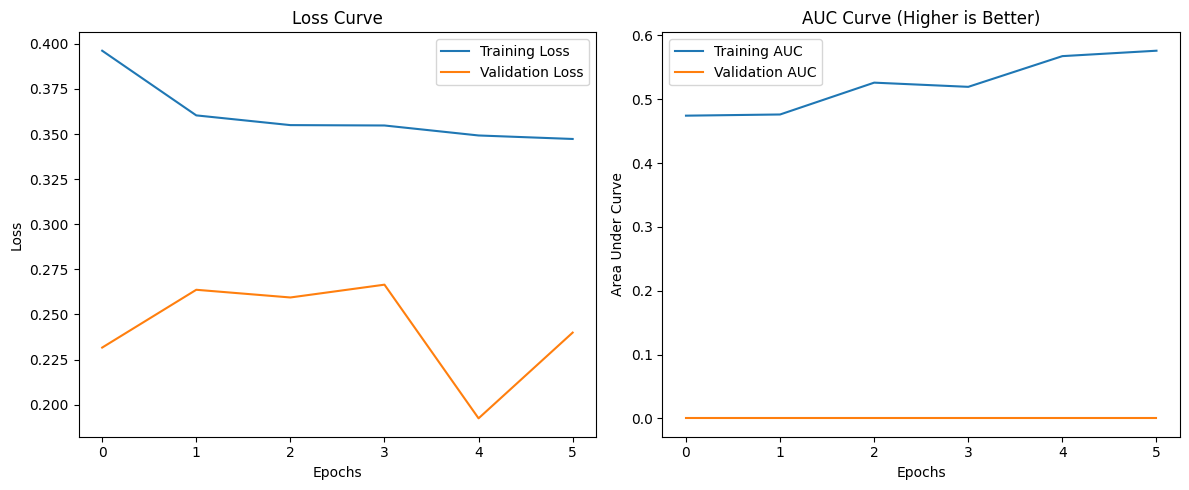


Model saved successfully to: d:\B\PA\projectv1.0\Urban_Flood_EWS\models\temporal\pune_lstm_v1.keras


In [12]:
import os
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import AUC, Recall
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import matplotlib.pyplot as plt

# 1. Handle Class Imbalance (With Capping to prevent gradient thrashing)
if y_train.sum() > 0:
    class_weights_array = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    # Cap the flood weight at 20.0 so the model cares, but doesn't panic
    adjusted_weights = {0: class_weights_array[0], 1: min(class_weights_array[1], 20.0)}
    print(f"Adjusted Class Weights applied: {adjusted_weights}")
else:
    print("WARNING: No flood data in training set. Cannot compute class weights.")
    adjusted_weights = None

# 2. Build the Regularized LSTM Architecture
model = Sequential([
    # Just ONE small LSTM layer to prevent memorization
    LSTM(16, return_sequences=False, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.4), # High dropout to force generalization
    
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 3. Compile with targeted metrics (Dropping 'accuracy')
# Lower learning rate (0.0005) for smoother weight updates
model.compile(optimizer=Adam(learning_rate=0.0005), 
              loss='binary_crossentropy', 
              metrics=[AUC(name='auc'), Recall(name='recall')])

# 4. Add the Emergency Brake (Early Stopping)
# Now monitoring 'val_auc' to maximize it, waiting 5 epochs before stopping
brake = EarlyStopping(monitor='val_auc', mode='max', patience=5, restore_best_weights=True)

# 5. Train the Brain
print("\nInitiating Deep Learning Training...")
history = model.fit(
    X_train, y_train,
    epochs=30,          
    batch_size=256,     
    validation_data=(X_test, y_test),
    class_weight=adjusted_weights,
    callbacks=[brake], 
    verbose=1
)

# 6. Plot the Healthy Loss and AUC Curves
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot AUC
plt.subplot(1, 2, 2)
plt.plot(history.history['auc'], label='Training AUC')
plt.plot(history.history['val_auc'], label='Validation AUC')
plt.title('AUC Curve (Higher is Better)')
plt.xlabel('Epochs')
plt.ylabel('Area Under Curve')
plt.legend()

plt.tight_layout()
plt.show()

# 7. Save the Temporal Model
os.makedirs(os.path.join(project_root, "models", "temporal"), exist_ok=True)
model_path = os.path.join(project_root, "models", "temporal", f"{city}_lstm_v1.keras") # .keras is the new standard extension
model.save(model_path)
print(f"\nModel saved successfully to: {model_path}")